In [73]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import math

In [ ]:
class Point:
    x = None
    y = None

    def __init__(self,coor_x,coor_y):
        self.x=coor_x
        self.y=coor_y

    def __lt__(self,other): # < -> This time we want the leftmost element
        if self.x != other.x :
            return self.x < other.x
        else:
            return self.y < other.y

    def plot(self, tag='', color=''): 
        kwargs = {} # A modification of the original class, allows passing independent arguments
        if color:
            kwargs['c'] = color
        if tag:
            kwargs['label'] = tag

        plt.scatter(self.x, self.y, **kwargs)
            
        if tag:
            plt.legend()

    def dist(self,other):
        return math.sqrt((self.x-other.x)**2 + (self.y-other.y)**2)


In [75]:
import os

instances = []

files = os.listdir(os.getcwd() + "/instancias")
for file in files:
    instance = []
    opened_file = open(os.getcwd() + "/instancias/" + file, "r") 
    n = int(opened_file.readline().strip())

    for _ in range(n):
        line = opened_file.readline().strip()
        x, y = map(float, line.split())
        point = Point(x, y)
        instance.append(point)
    opened_file.close()
    instances.append((file,instance))


## JARVIS
Jarvis algorithm, also known as (gift wrapping) is a popular algorithm that solves the Convex Hull problem that consists on:

#### Convex Hull
Given a 2D array points[][] of n distinct points, where points[i] = [xi, yi] represents a point in a 2D plane, find the vertices of the convex hull of these points. The convex hull is the smallest convex polygon that contains all the points, either inside it or on its boundary.

### Time complexity
Due to the fact that we iterate through all points in the set and compare against all the other remaining points. The time complexity
of this algorithm is O(n^2)

## Space complexity
We store the hull elements, this one can be at most the same length of the original set, this produces an aditional space complexity of:
O(n)

## Differences against other algorithms
This algorithm uses a brute-force aproach matching all combinations of sets of 3 elements, producing a high time complexity, which is resolved by algorithms like the graham's scan (greedy with O(nlogn)) or the quickhull(divide and conquer with a complexity O(nlogn-n²))

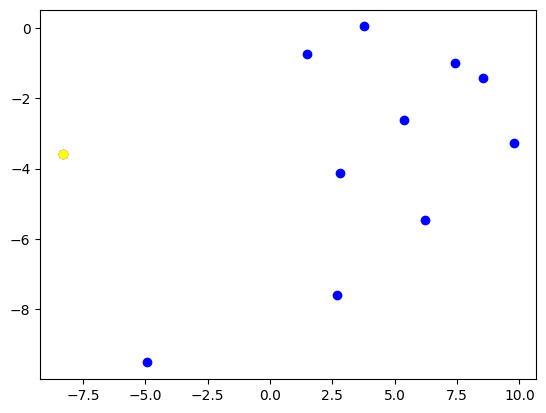

In [76]:
points = instances[0][1]

#Compared with other algorithms, this one uses the leftmost element of the set
lower = min(points)
for p in points:
    p.plot(color='b')

lower.plot(color='yellow')

In [77]:
# Orientation: Helps to identify if the points are in clockwise or counterclockwise order
# Time complexity: O(1)
# Space complexity: O(1)
def orientation(p, q, r):
    val = (q.y - p.y) * (r.x - q.x) - (q.x - p.x) * (r.y - q.y)
    if val == 0:
        return 0  # collinear
    elif val > 0:
        return 1  # clockwise
    else:
        return 2  # counterclockwise

In [78]:
def jarvis(points):
    on_hull = min(points) # Our first element, this one is the leftmost point between all points
    hull = [] # Defines our array of points
    while True:
        hull.append(on_hull)
        next_point = points[0]
        for point in points:
            o = orientation(on_hull,next_point,point)
            if next_point == on_hull or o==1 or (o==0 and  on_hull.dist(point) ) > on_hull.dist(next_point):

                # If its clockwise or, the current next point is the last one added to the hull, or if they are colinear and theres a further point
                next_point = point
        on_hull= next_point
        if on_hull == hull[0]:
            break
    return hull

In [88]:
def convex_hull(file, points):
    fig, ax = plt.subplots()
    lower = min(points)
    for p in points:
        p.plot(color='blue')

    lower.plot(color='yellow', tag='begin') # First point of the hull, the leftmost point

    # Calculate the hull
    hull_points = jarvis(points)
    hull_coords=[(p.x,p.y) for p in  hull_points]
    hull = Polygon(hull_coords, closed=True, facecolor='lightgreen', edgecolor='darkgreen', alpha=0.3) # Plot the hull resulting of jarvis algorithm
    ax.add_patch(hull)
    plt.title(file)
    plt.show()

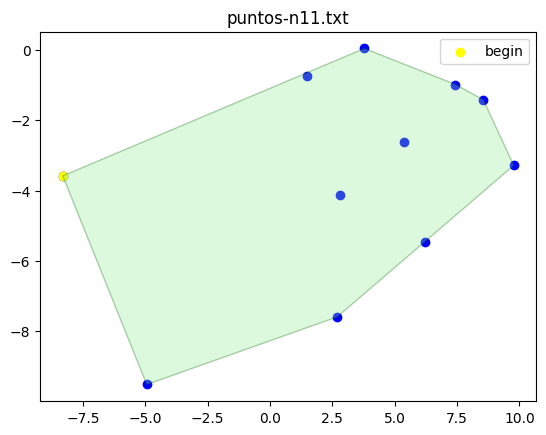

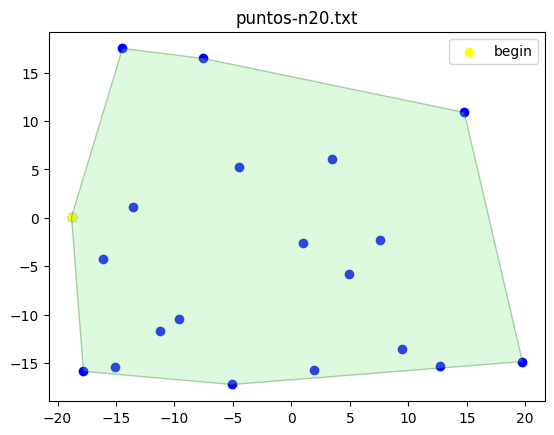

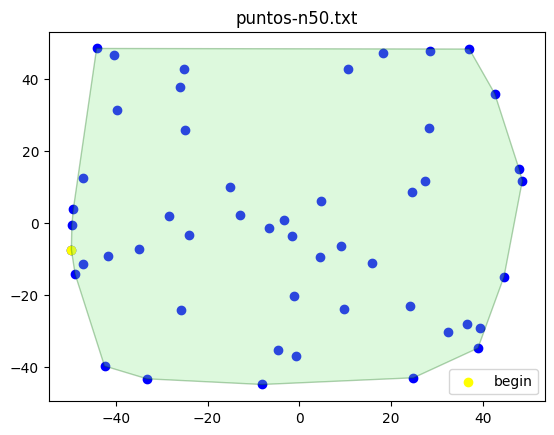

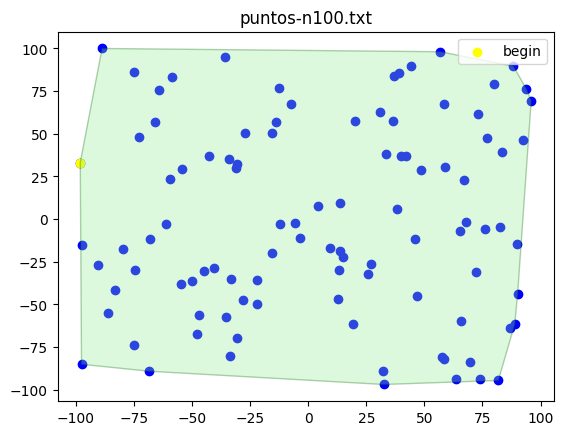

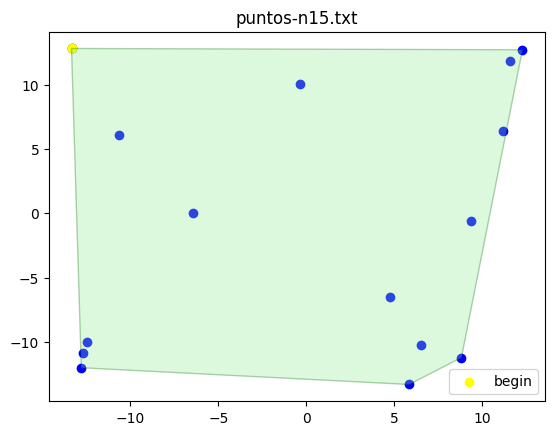

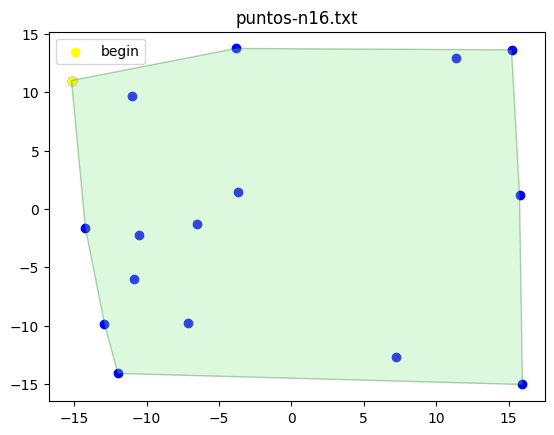

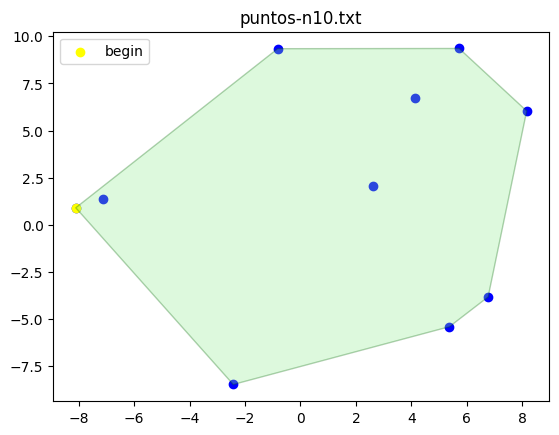

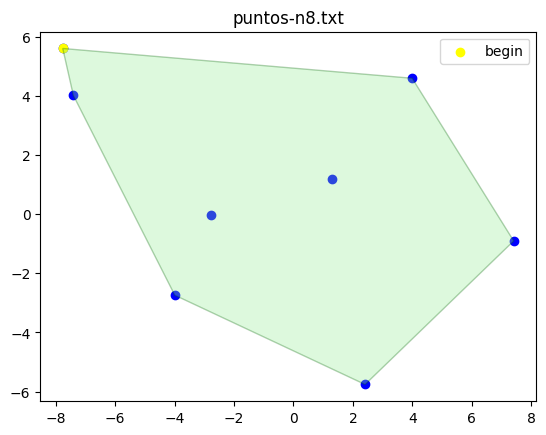

In [89]:
for instance in instances:
    convex_hull(instance[0],instance[1])

## References
https://www.geeksforgeeks.org/dsa/convex-hull-using-graham-scan/
https://www.geeksforgeeks.org/dsa/convex-hull-using-jarvis-algorithm-or-wrapping/
https://youtu.be/nBvCZi34F_o